# Capital Bikeshare next-day rental forecast

**Decision question.** Can a simple model reduce one-day-ahead planning error compared with repeating yesterday's rentals or the count from the same day last week?

The study uses 731 consecutive historical days from the UCI Bike Sharing dataset. The evaluation uses September through December 2012. See [data provenance](data/README.md).

In [1]:
from pathlib import Path
from tempfile import TemporaryDirectory

import pandas as pd
from IPython.display import Image, display

from bike_forecast import (
    DEFAULT_DATA, TEST_START, backtest, build_features, evaluate,
    evaluate_by_day_type, plot_backtest, prepare_daily,
)

daily = prepare_daily(pd.read_csv(DEFAULT_DATA))
features = build_features(daily)
print(f"{len(daily)} days from {daily.index.min().date()} to {daily.index.max().date()}.")
features.head(5)

731 days from 2011-01-01 to 2012-12-31.


,actual,lag_1,lag_7,mean_previous_7,weekend,annual_sin,annual_cos
date,,,,,,,
2011-01-08,959,1510.0,985.0,1344.714286,1,0.120126,0.992759
2011-01-09,822,959.0,801.0,1341.000000,1,0.137185,0.990545
2011-01-10,1321,822.0,1349.0,1344.000000,0,0.154204,0.988039
2011-01-11,1263,1321.0,1562.0,1340.000000,0,0.171177,0.985240
2011-01-12,1162,1263.0,1600.0,1297.285714,0,0.188099,0.982150


## Use only information available before each forecast

For day *t*, use rentals on *t − 1* and *t − 7*, the mean through *t − 1*, a weekend flag, and a cyclical representation of the day of year. Shift the target before the rolling average. Same-day weather and the user categories that sum to the target stay out of the model.

Fit Ridge and its scaler once on the dates before September 2012. In the holdout, observe each day's count after predicting it and allow that count to inform the following day's prediction. The evaluation represents repeated one-day forecasts with updated history.

In [2]:
predictions = backtest(features)
print(f"Training days: {(features.index < TEST_START).sum()}. Holdout days: {len(predictions)}.")
display(evaluate(predictions).round(1), evaluate_by_day_type(predictions).round(1))

Training days: 602. Holdout days: 122.


,mae,bias
method,,
yesterday,916.4,37.9
last_week,1325.5,291.0
ridge,922.9,-102.5


mae   bias  days
day_type method                        
Weekday  yesterday   855.2 -170.8    86
         last_week  1303.7  317.7    86
         ridge       874.7 -161.2    86
Weekend  yesterday  1062.5  536.3    36
         last_week  1377.8  227.0    36
         ridge      1037.9   37.6    36

## Measure the error in rentals per day

Mean absolute error (MAE) is the average number of rentals by which a prediction misses. Mean bias retains the sign. Negative bias means predicted counts are lower on average. Weekday and weekend rows test whether one aggregate score hides a weaker segment.

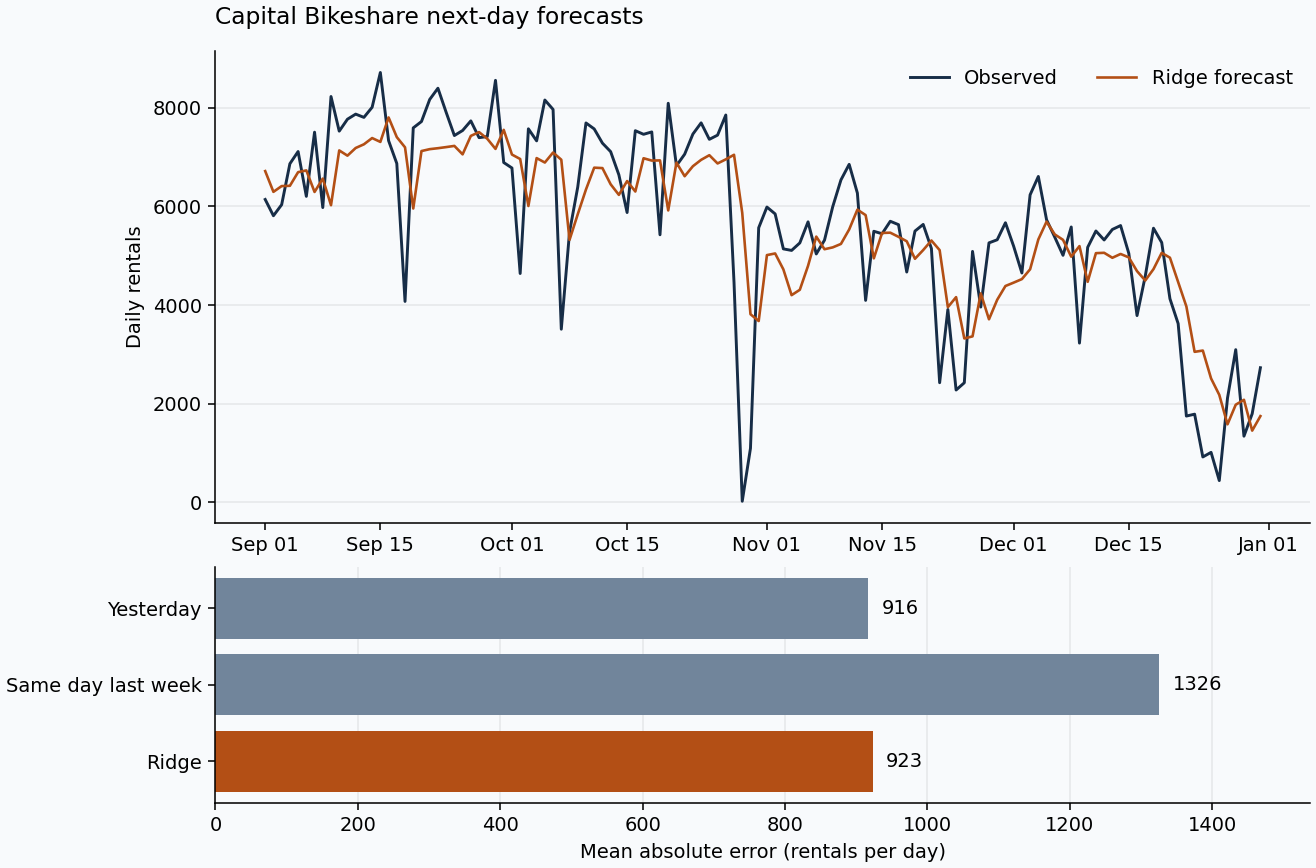

In [3]:
with TemporaryDirectory(dir=Path.cwd()) as directory:
    chart = Path(directory) / "forecast-backtest.png"
    plot_backtest(predictions, chart)
    display(Image(filename=str(chart), width=860))

In [4]:
scores = evaluate(predictions)["mae"]
baseline = scores.drop(index="ridge").idxmin()
improvement = 100 * (scores[baseline] - scores["ridge"]) / scores[baseline]
worst = (predictions["ridge"] - predictions["actual"]).abs().idxmax()
print(f"Ridge MAE: {scores['ridge']:.1f} rentals/day.")
print(f"Relative MAE reduction vs {baseline}: {improvement:.1f}%.")
print(f"Largest Ridge miss: {worst.date()}")
display(predictions.loc[[worst]].round(1))

Ridge MAE: 922.9 rentals/day.
Relative MAE reduction vs yesterday: -0.7%.
Largest Ridge miss: 2012-10-29


,actual,yesterday,last_week,ridge
date,,,,
2012-10-29,22,4459.0,7058.0,5867.6


## Apply the results within the scope of the data

A lower holdout MAE supports testing this approach on newer rental data. The model is citywide and the records are historical. Station-level inventory decisions would require station-level trips and capacity, plus a newer evaluation period. Weather forecasts and holiday indicators are candidates for a future evaluation, especially for sudden demand changes.